# Helium probe: from a measured sweep to electron energies

This notebook actively reconstructs all 304 Beckers2017 samples with cleaned local mathematics. It identifies the acquired current, original method outputs, and freshly recovered distribution separately. The reference is a reproduced analysis of the same measurement, **not ground truth**. No independent electron-distribution measurement is supplied. The published collection assumptions can therefore be checked for consistency, but their physical accuracy cannot be inferred from parity alone.

## 1. Observation and acquisition

A cylindrical electrode with length 1.145 mm and diameter 1.57 mm collects electrons and ions in helium plasma. The full characteristic has the author's smoothing already applied; its kernel and unsmoothed precursor are unavailable. Positive current denotes electron collection. We use all samples to differentiate and estimate the characteristic potentials.

In [1]:
from pathlib import Path
import sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'src').is_dir(): root=root.parent
sys.path.insert(0,str(root))
from src.main import run
from src.preprocessing import load_data,PROBE_AREA_M2
from src.solvers import reconstruct,fit_temperature
from src.physics_model import electron_current
from src.visualization import observation_figure,fit_figure,distribution_figure,sensitivity_figure
v,i=load_data(root/'data/raw_data.npz')
print('Active Python:',sys.executable,'NumPy:',np.__version__)
print('Full observation:',v.shape,'area (m²):',PROBE_AREA_M2)
plt.rcParams.update({'figure.dpi':110,'font.size':10})

Active Python: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe NumPy: 2.4.6
Full observation: (304,) area (m²): 7.583411966684061e-06


## 2. Physics and implemented inversion

The measured current is $I=I_i+I_e$. The orbital-motion-limited ion relation fits squared current linearly in voltage. Subtracting this fitted ion current reveals a retarding electron current with $\log I_e=y+(V-x)/T$. The slope recovers temperature $T$ in eV. A first fit uses the strict interval $V_F<V<V_P$ and gives temperature $T_1$. The second fit uses $V_F+1.5T_1<V<V_P-0.2T_1$, with numerical eV temperatures interpreted as voltage scales. The native algorithm uses the minimum absolute current sample for floating potential $V_F$ and the maximum full-sweep current derivative for plasma potential $V_P$. Derivatives use centered nonuniform interior differences and first-order one-sided endpoint differences, selecting the first sample in any tie.

The distribution is obtained from the second full-sweep derivative:

$$
E=V_P-V,\qquad p(E)=\sqrt E\frac{d^2I}{dV^2},\qquad
f(E)=\frac{p(E)}{\left|\int p(E)\,dE\right|}.
$$

Here $V_P$ is plasma potential in V, $E$ is numerical energy in eV, and $f$ is normalized density per eV. Strict floating-to-plasma selection is performed after differentiation. The native method differentiates total measured current, approximating the ion contribution to curvature as negligible; it does not first subtract ions for this distribution calculation. We preserve this convention and expose it as a model limitation. No derivative clipping or additional smoothing is applied.

Fresh complete inverse runtime (s): 0.004138899967074394


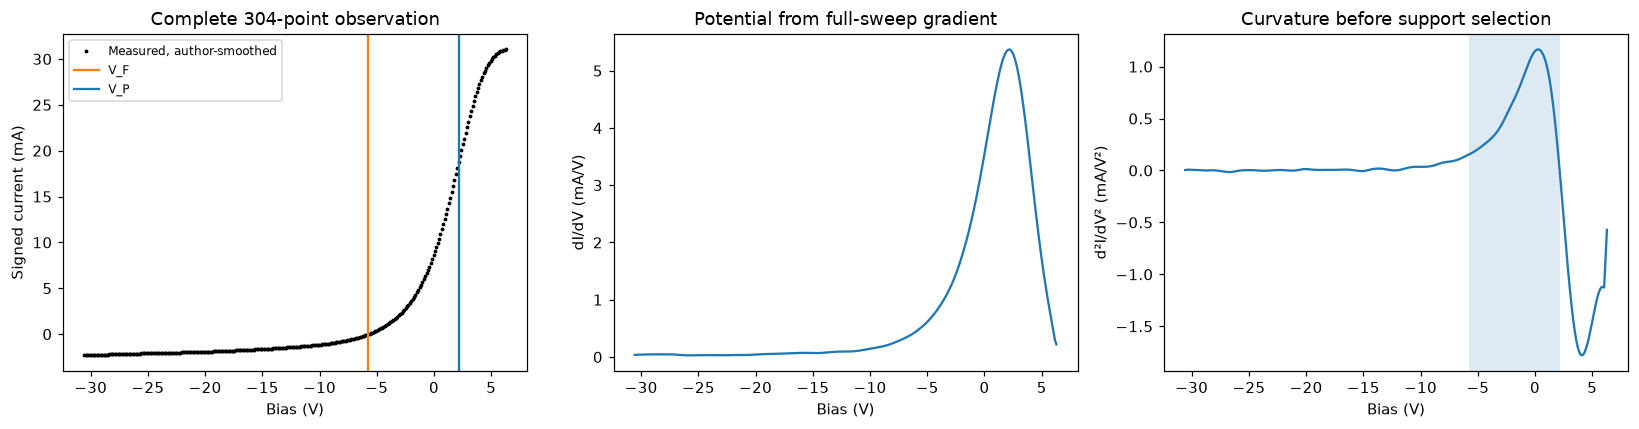

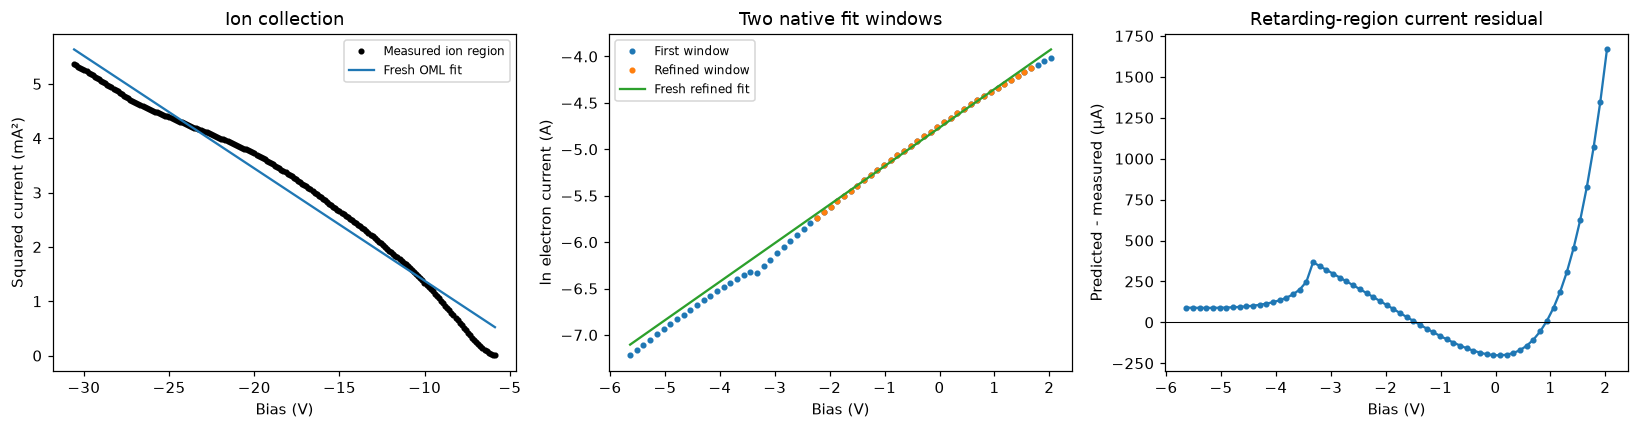

In [2]:
start=time.perf_counter()
fresh,d,runtime=run(root/'data/raw_data.npz',root/'output/reconstruction.npz')
print('Fresh complete inverse runtime (s):',runtime)
observation_figure(v,i,fresh,d);plt.show()
fit_figure(v,i,fresh,d);plt.show()

## 3. Reference role and fresh comparison

The original PlasmaPy implementation ran independently on this exact characteristic before any local extraction. Its saved outputs are loaded below solely to compare numerical results. Both methods use the same measured data and model, so agreement is reproducibility evidence. The ideal Maxwellian curve is computed from the freshly recovered temperature and normalized on the same measured interval. Its difference from the derivative distribution probes the single-temperature model rather than comparing to true plasma energies.

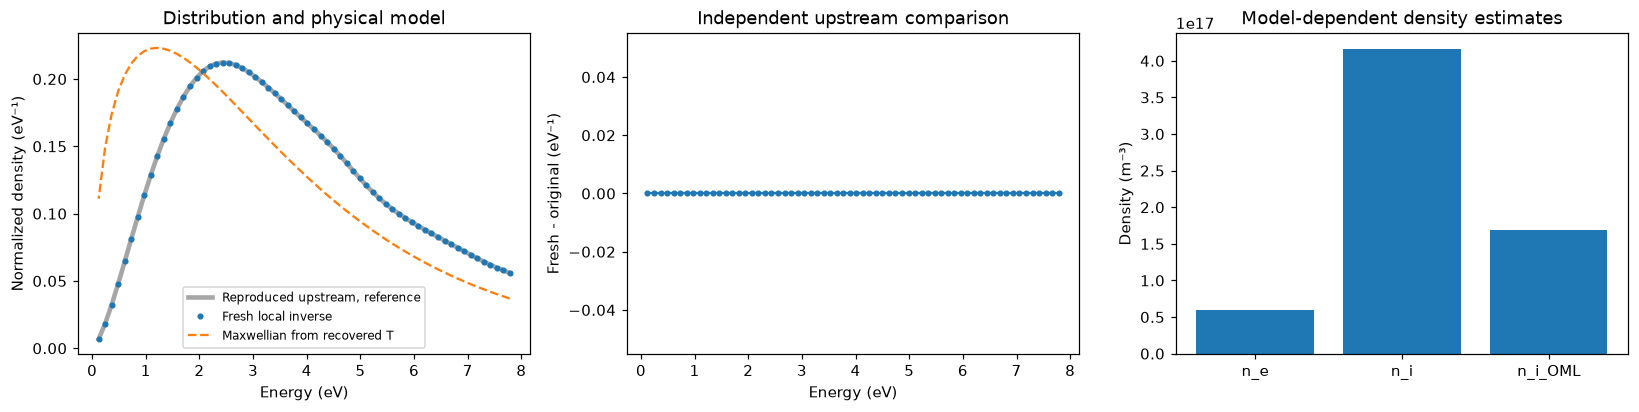

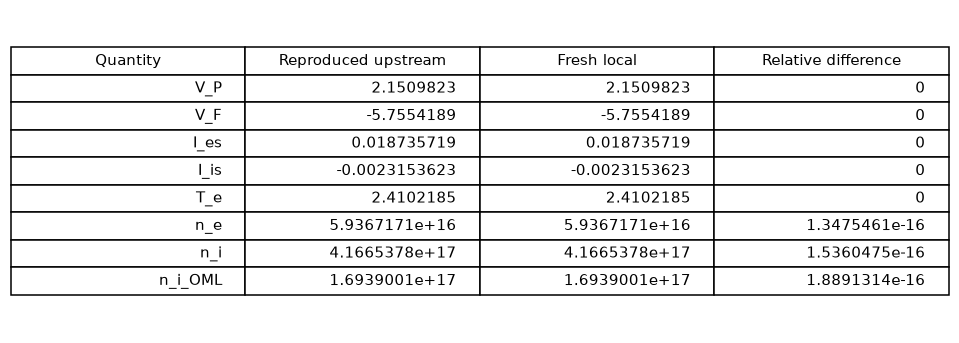

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "eedf_relative_l2": 0.0,
    "energy_max_abs": 0.0,
    "parameter_max_relative": 1.8891314354156382e-16,
    "normalization_error": 2.220446049250313e-16
  },
  "thresholds": {
    "eedf_relative_l2": {
      "comparison": "<=",
      "boundary": 1e-07
    },
    "energy_max_abs": {
      "comparison": "<=",
      "boundary": 1e-10
    },
    "parameter_max_relative": {
      "comparison": "<=",
      "boundary": 1e-06
    },
    "normalization_error": {
      "comparison": "<=",
      "boundary": 1e-07
    }
  },
  "errors": []
}


752

In [3]:
with np.load(root/'notebooks/reference_outputs/upstream.npz',allow_pickle=False) as z:
    upstream={k:z[k].copy() for k in z.files}
distribution_figure(fresh,upstream);plt.show()
spec=importlib.util.spec_from_file_location('standalone_judge',root/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exitcode=judge.evaluate(root/'output/reconstruction.npz')
assert exitcode==0,report
rows=[]
for key in ['V_P','V_F','I_es','I_is','T_e','n_e','n_i','n_i_OML']:
    a=float(upstream[key].ravel()[0]);b=float(fresh[key][0,0])
    rows.append([key,a,b,abs(b-a)/abs(a)])
fig,ax=plt.subplots(figsize=(11,3.8));ax.axis('off')
tab=ax.table(cellText=[[r[0]]+[f'{x:.8g}' for x in r[1:]] for r in rows],colLabels=['Quantity','Reproduced upstream','Fresh local','Relative difference'],loc='center')
tab.auto_set_font_size(False);tab.set_fontsize(10);tab.scale(1,1.5);plt.show()
print(json.dumps(report,indent=2))
(root/'notebooks/reference_outputs/fresh_metrics.json').write_text(json.dumps({'role':'fresh cleaned run, not truth','runtime_seconds':runtime,'judge':report},indent=2),encoding='utf8')

## 4. Current residual and fit-window ablation

A current residual tests the collection approximation in the retarding region. The exponential model is not valid across the entire electron-saturation branch, so the residual metric below is explicitly restricted to the native retarding support; the preceding observation figure still shows the complete acquisition. The original display-only NaN mask above maximum measured current is replaced only by finite mathematical extrapolation for plotting and is never part of the inversion.

The first fit uses the full retarding interval. The refined fit uses the initial temperature to exclude transitions. Both fits below are computed afresh. Their measured current residual and recovered temperature show how window choice affects this exact observation.

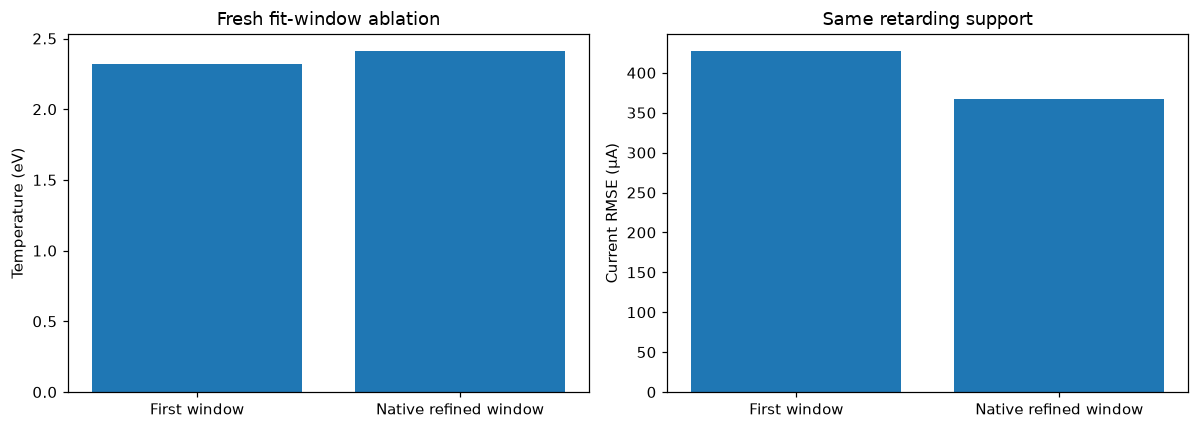

Method, temperature eV, current RMSE A, L2-relative current residual:
['First window', 2.320833441149439, 0.00042703907017933667, 0.055171165476270156]
['Native refined window', 2.410218469433933, 0.00036726772369264585, 0.047449026969430874]
Density ratios ne/OML and Bohm/OML: 0.3504762135645043 2.459730488162936


In [4]:
firstfit=d['first_fit'];refinedfit=d['electron_fit'];mask=d['first_mask']
comparisons=[]
for label,fit in [('First window',firstfit),('Native refined window',refinedfit)]:
    prediction=electron_current(v,fit)+d['ion_current']
    residual=prediction[mask]-i[mask]
    comparisons.append([label,float(fit[2]),float(np.sqrt(np.mean(residual**2))),float(np.linalg.norm(residual)/np.linalg.norm(i[mask]))])
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].bar([r[0] for r in comparisons],[r[1] for r in comparisons]);ax[0].set(ylabel='Temperature (eV)',title='Fresh fit-window ablation')
ax[1].bar([r[0] for r in comparisons],[r[2]*1e6 for r in comparisons]);ax[1].set(ylabel='Current RMSE (µA)',title='Same retarding support')
fig.tight_layout();plt.show()
print('Method, temperature eV, current RMSE A, L2-relative current residual:')
for row in comparisons: print(row)
print('Density ratios ne/OML and Bohm/OML:',float(fresh['n_e'][0,0]/fresh['n_i_OML'][0,0]),float(fresh['n_i'][0,0]/fresh['n_i_OML'][0,0]))

## 5. Perturbation robustness and sampling ablation

The following computations add noise to the measured characteristic and rerun every local stage, including potential and window selection. These are controlled sensitivity experiments, not estimates of the instrument's noise or physical confidence intervals. EEDF comparison uses only overlap of each recovered energy support and interpolation for this sensitivity plot; the benchmark Judge performs no interpolation or alignment. The native distribution normalization preserves negative curvature, so perturbed estimates can have negative values.

Subsampling every second and third voltage sample independently changes numerical differentiation. It is an ablation, not a replacement for the complete benchmark reconstruction.

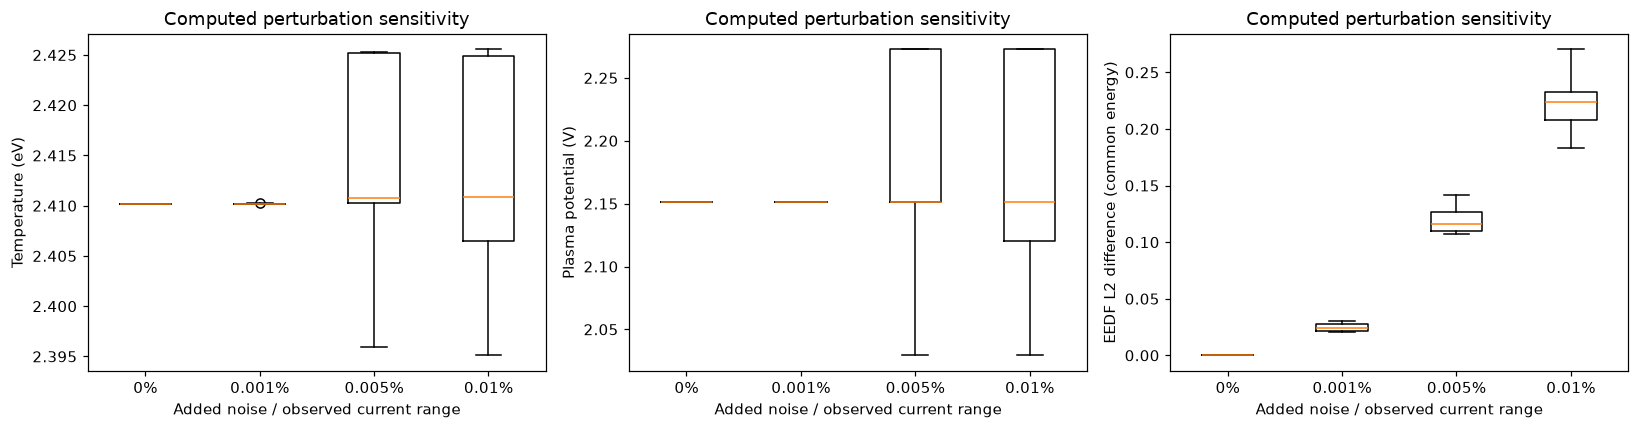

Completed sensitivity inversions: 32 explicit failures: []


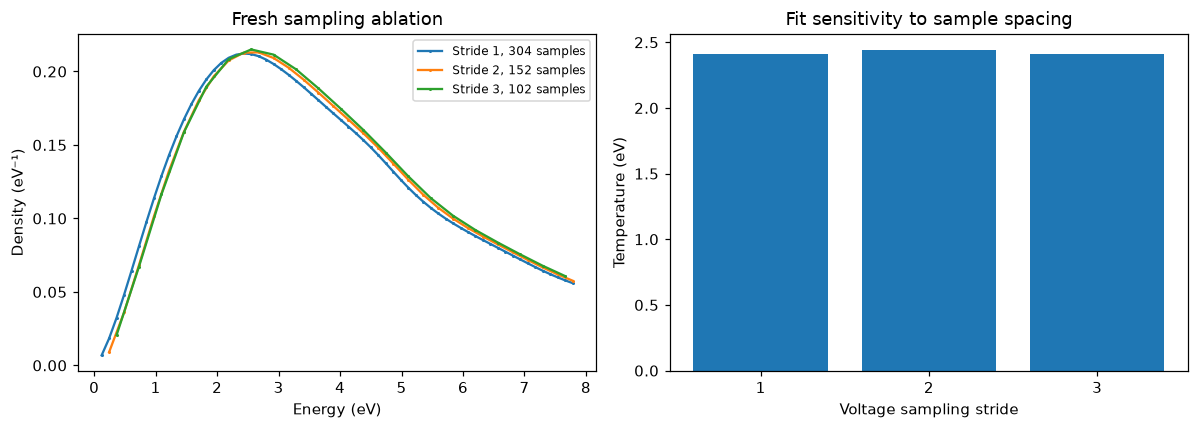

[{'stride': 1, 'samples': 304, 'temperature_eV': 2.410218469433933, 'negative_fraction': 0.0}, {'stride': 2, 'samples': 152, 'temperature_eV': 2.439813019393585, 'negative_fraction': 0.0}, {'stride': 3, 'samples': 102, 'temperature_eV': 2.410093825027838, 'negative_fraction': 0.0}]


7971

In [5]:
rng=np.random.default_rng(20261026);records=[];failures=[]
baseline_energy=fresh['energy'][0];baseline_p=fresh['reconstruction'][0]
for fraction in [0.,1e-5,5e-5,1e-4]:
    for repeat in range(8):
        noisy=i+rng.normal(0,fraction*np.ptp(i),size=i.shape)
        try:
            out,diag=reconstruct(v,noisy)
            ee=out['energy'][0];pp=out['reconstruction'][0]
            use=(baseline_energy>=ee.min())&(baseline_energy<=ee.max())
            if use.sum()<3: raise ValueError('Insufficient common support')
            interp=np.interp(baseline_energy[use],ee[::-1],pp[::-1])
            difference=np.linalg.norm(interp-baseline_p[use])/np.linalg.norm(baseline_p[use])
            records.append(dict(noise_fraction=fraction,repeat=repeat,T_e=float(out['T_e'][0,0]),V_P=float(out['V_P'][0,0]),eedf_difference=float(difference),negative_fraction=float(np.mean(pp<0))))
        except Exception as exc: failures.append(dict(noise_fraction=fraction,repeat=repeat,error=str(exc)))
sensitivity_figure(records);plt.show()
print('Completed sensitivity inversions:',len(records),'explicit failures:',failures)
fig,ax=plt.subplots(1,2,figsize=(11,4))
sampling=[]
for stride in [1,2,3]:
    out,diag=reconstruct(v[::stride],i[::stride]);sampling.append({'stride':stride,'samples':len(v[::stride]),'temperature_eV':float(out['T_e'][0,0]),'negative_fraction':float(np.mean(out['reconstruction']<0))})
    ax[0].plot(out['energy'][0],out['reconstruction'][0],'.-',ms=2,label=f'Stride {stride}, {len(v[::stride])} samples')
ax[0].set(xlabel='Energy (eV)',ylabel='Density (eV⁻¹)',title='Fresh sampling ablation');ax[0].legend(fontsize=8)
ax[1].bar([str(s['stride']) for s in sampling],[s['temperature_eV'] for s in sampling]);ax[1].set(xlabel='Voltage sampling stride',ylabel='Temperature (eV)',title='Fit sensitivity to sample spacing')
fig.tight_layout();plt.show()
print(sampling)
(root/'notebooks/reference_outputs/fresh_metrics.json').write_text(json.dumps({'role':'fresh cleaned run, not truth','runtime_seconds':runtime,'judge':report,'fit_ablation':comparisons,'noise_records':records,'noise_failures':failures,'sampling_ablation':sampling},indent=2),encoding='utf8')

## 6. Interpretation and limitations

The fresh local inversion reproduces the original numerical analysis while exposing its acquisition equations and units. Current-fit and ideal-Maxwellian comparisons examine physical consistency; neither creates missing ground truth. Differences among the density estimates reflect collection-model and saturation-current approximations and must remain visible. The electron saturation estimate uses the observed total current at the gradient maximum, following the native method.

Differentiation strongly amplifies perturbations, and recovered support can change when a perturbed sweep changes the characteristic potential. The normalized EEDF describes only the measured interval and uses the author's existing smoothing. The noise and sampling studies quantify numerical sensitivity of this task rather than general plasma diagnostic accuracy. All benchmark outputs above came from a fresh full-sweep computation.